# Phase 2 — descriptive lung transcriptomics
Patient-level exploratory analysis of GSE131907. No claim of measured T-cell suppression or causal target validation. See the protocol and manifest for definitions and provenance.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'results/run_manifest.json').exists()
manifest=json.loads((ROOT/'results/run_manifest.json').read_text())
{k:manifest[k] for k in ['patients','input_cells','retained_cells','tested_genes','primary_fdr_005','composition_fdr_005']}

{'patients': 11,
 'input_cells': 45149,
 'retained_cells': 44984,
 'tested_genes': 6124,
 'primary_fdr_005': 0,
 'composition_fdr_005': 1}

## Reproduce
Install requirements-lock.txt in Python 3.11, download the three GEO files documented in README.md, then run the cell below with RUN_PIPELINE=True. The executed notebook uses the already completed outputs rather than silently recalculating them.

In [2]:
RUN_PIPELINE=False
if RUN_PIPELINE:
    import subprocess, sys
    subprocess.run([sys.executable, str(ROOT/'phase2.py')],cwd=ROOT,check=True)

In [3]:
display(pd.read_csv(ROOT/'results/qc_summary.csv'))
display(pd.read_csv(ROOT/'results/patient_features.csv'))

,Sample,input_cells,qc_pass,doublets,retained,median_umi,median_genes,median_mito
0,LUNG_T06,3426,3426,4,3422,3837.5,1194.5,0.037179
1,LUNG_T08,3765,3765,37,3728,3479.0,1082.0,0.036008
2,LUNG_T09,3840,3840,4,3836,3807.5,1197.0,0.037109
3,LUNG_T18,3705,3705,7,3698,4096.0,1386.0,0.037148
4,LUNG_T19,4361,4361,8,4353,4053.0,1198.0,0.034659
5,LUNG_T20,4021,4021,0,4021,2966.0,1073.0,0.038637
6,LUNG_T25,4374,4374,35,4339,3016.0,927.0,0.033646
7,LUNG_T28,4705,4705,6,4699,3258.0,1126.0,0.042705
8,LUNG_T30,4094,4094,47,4047,2697.0,1026.0,0.005071
9,LUNG_T31,5578,5578,3,5575,2203.0,861.0,0.028977


,sample,patient_id,macrophages,T_cells,CD8_cells,mo_fraction,t_inhibitory,cd8_inhibitory,t_cytotoxic,mac_lipid,mac_antigen,age,sex_male,double_histology,log_mac_umi
0,LUNG_T06,P0006,224,1498,179,0.955357,0.166425,0.311873,0.534949,1.729777,3.864630,54,1,False,9.100855
1,LUNG_T08,P0008,141,2101,96,1.000000,0.172967,0.380581,0.211185,1.533935,4.030366,60,0,False,8.928893
2,LUNG_T09,P0009,1146,1877,759,0.970332,0.226204,0.328534,1.068098,2.028184,3.711223,67,1,False,9.527163
3,LUNG_T18,P0018,773,1029,184,0.984476,0.221633,0.332925,0.685771,2.302468,3.671971,62,1,False,8.678218
4,LUNG_T19,P0019,731,1523,100,0.447332,0.131722,0.198201,0.302050,1.229798,3.895242,53,1,False,9.442250
5,LUNG_T20,P0020,634,2338,393,0.878549,0.251108,0.361943,0.788425,1.659785,3.937046,55,1,False,9.321241
6,LUNG_T25,P0025,383,1515,109,0.984334,0.217415,0.240678,0.194004,1.560155,3.581045,69,1,True,9.068612
7,LUNG_T28,P0028,843,1526,364,0.966785,0.268648,0.432445,1.055840,1.605277,3.309838,73,1,True,8.458193
8,LUNG_T30,P0030,686,1270,71,0.069971,0.173205,0.223197,0.402586,1.232360,4.098716,56,1,False,8.984332
9,LUNG_T31,P0031,229,3582,102,0.930131,0.180445,0.338493,0.913562,1.528143,4.053404,65,1,False,8.938167


In [4]:
candidates=pd.read_csv(ROOT/'results/transcriptomic_candidates.csv')
display(candidates.head(20))

,gene_id,gene_symbol,cohort_id,patient_n,macrophage_programme,t_cell_programme,association_effect,association_se,p_value,fdr,...,composition_adjusted_fdr,within_state_effect,within_state_p,within_state_fdr,detection_fraction,model_id,within_state_patient_n,loo_effect_min,loo_effect_max,loo_sign_fraction
0,NaN,GLTSCR2,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.754008,0.091198,0.000017,0.069382,...,0.325459,-0.693992,0.000061,0.093245,0.727622,patient_OLS_HC3_v1,10,-0.867473,-0.612468,1.0
1,HGNC:18076,ARL6IP4,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.781611,0.097988,0.000023,0.069382,...,0.156554,-0.518303,0.277736,0.999985,0.816132,patient_OLS_HC3_v1,10,-0.841464,-0.659528,1.0
2,HGNC:9629,PTMS,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.896665,0.126110,0.000056,0.114398,...,0.536842,-0.660856,0.034183,0.999985,0.705912,patient_OLS_HC3_v1,10,-0.926605,-0.849886,1.0
3,NaN,C6orf48,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.766989,0.113495,0.000083,0.126927,...,0.425685,-0.652550,0.002443,0.999985,0.594355,patient_OLS_HC3_v1,10,-0.858567,-0.638825,1.0
4,HGNC:269,ADPRH,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.837063,0.134047,0.000151,0.150214,...,0.435732,-0.579230,0.126121,0.999985,0.134603,patient_OLS_HC3_v1,10,-0.909434,-0.773644,1.0
5,HGNC:15822,OXR1,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.778896,0.126925,0.000171,0.150214,...,0.482707,-0.239129,0.404339,0.999985,0.162993,patient_OLS_HC3_v1,10,-0.898707,-0.667901,1.0
6,HGNC:14348,HTRA2,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.900964,0.147877,0.000181,0.150214,...,0.314319,-0.265986,0.608446,0.999985,0.143788,patient_OLS_HC3_v1,10,-0.922686,-0.856157,1.0
7,HGNC:6616,LIMS1,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,0.671214,0.111392,0.000196,0.150214,...,0.661005,0.601888,0.024143,0.999985,0.703073,patient_OLS_HC3_v1,10,0.522057,0.795398,1.0
8,HGNC:24974,TRMT2A,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.699977,0.126902,0.000372,0.229796,...,0.661005,-0.550674,0.082934,0.999985,0.129927,patient_OLS_HC3_v1,10,-0.814671,-0.509265,1.0
9,HGNC:19143,USP32,GSE131907_primary_lung,11,gene_mean_log1p_10k,t_inhibitory,-0.897032,0.162797,0.000375,0.229796,...,0.340305,-0.464190,0.261861,0.999985,0.185204,patient_OLS_HC3_v1,10,-0.929440,-0.857629,1.0


In [5]:
s=pd.read_csv(ROOT/'results/sensitivity_models.csv')
display(s.groupby('analysis').agg(patients=('patient_n','first'),genes=('gene_symbol','size'),fdr_005=('fdr',lambda x:(x<.05).sum())))

,patients,genes,fdr_005
analysis,,,
CD8,11,6124,4
adaptive_qc,11,6124,0
age,11,6124,0
cytotoxic,11,6124,0
exclude_double_histology,9,6124,0
library_size,11,6124,0
retain_doublets,11,6124,0
sex,11,6124,0
strict_T_annotation,11,6124,0


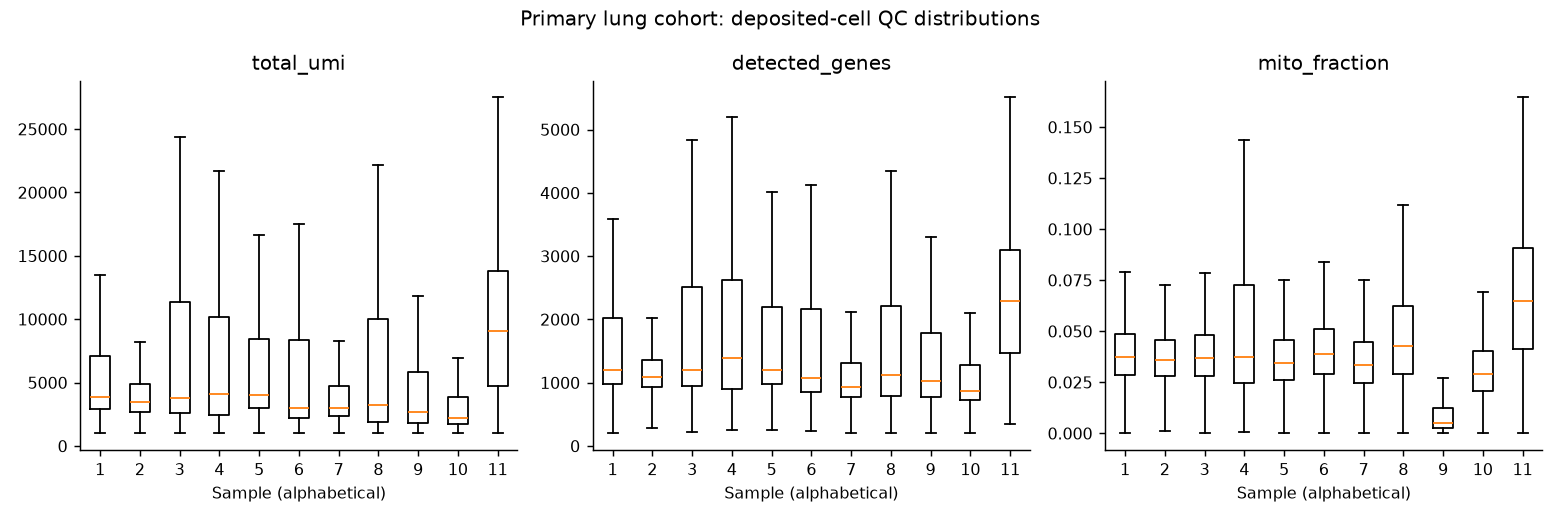

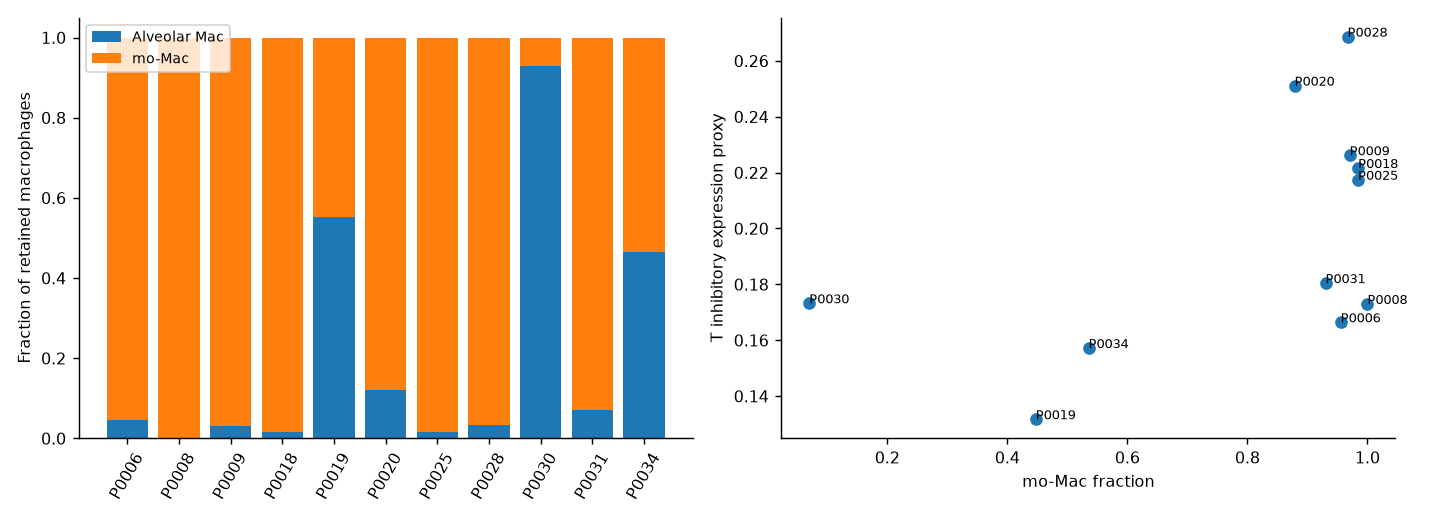

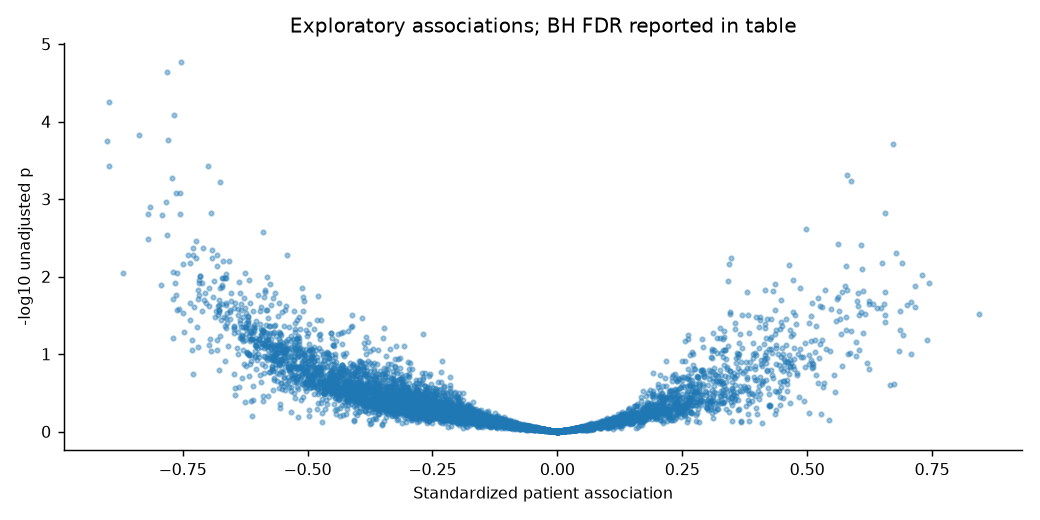

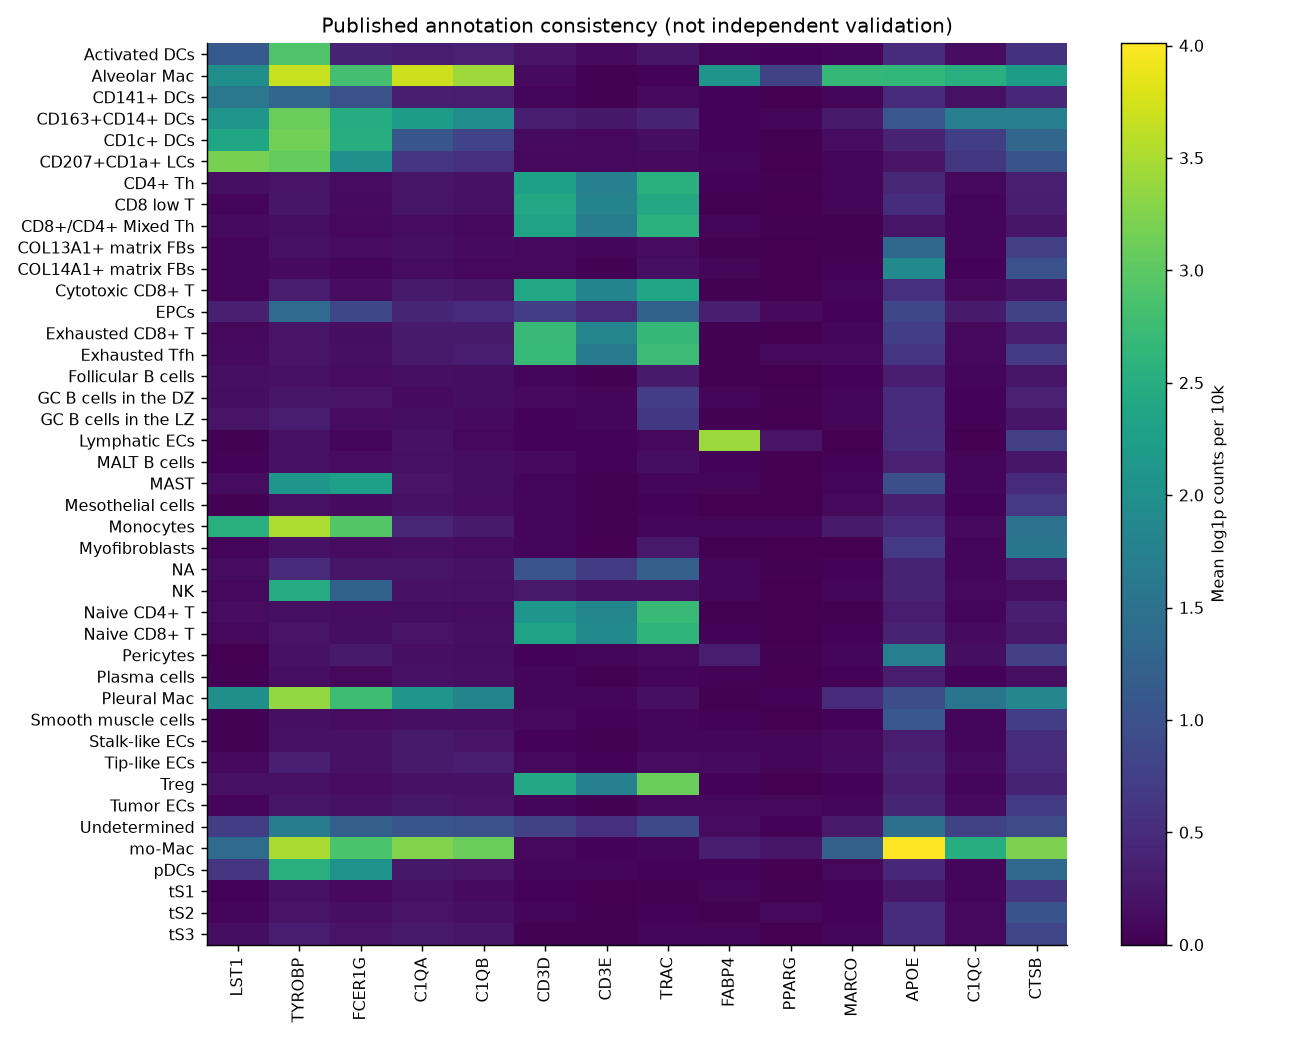

In [6]:
for name in ['qc','composition','associations','annotation']:
    display(Image(filename=str(ROOT/f'results/plots/{name}.png')))

## Limits
Only 11 patients from one cohort. Patient and capture effects cannot be independently estimated. Published annotations and marker checks are not independent validation. All-T-cell scores mix T-cell states; CD8 and cytotoxic sensitivities are separate. Doublet calls are uncertain. Associations and FDR are exploratory; absence of significance is not evidence of no biology.